## 1. Environment Setup and Library Imports
Import all necessary libraries for data manipulation, machine learning modeling (`scikit-learn`, `imblearn`), statistical analysis (`statsmodels`), visualization (`matplotlib`, `seaborn`), and mathematical optimization (`pulp`).

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
# MUST use imblearn pipeline to include SMOTE safely
from imblearn.pipeline import Pipeline as ImbPipeline 
from imblearn.over_sampling import SMOTE
import statsmodels.api as sm
import statsmodels.formula.api as smf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pulp
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

## 2. Load Cleaned Dataset
Load the preprocessed HMDA Loan Application Register (LAR) dataset and inspect its available column names.

In [2]:
# Load the cleaned data
df_lar_final = pd.read_csv("hmda_lar_2025_cleaned.csv")


In [3]:
df_lar_final.columns.to_list()

['lei',
 'census_tract',
 'action_taken',
 'target_denied',
 'loan_amount',
 'log_loan_amount',
 'income',
 'log_income',
 'income_to_tract_ratio',
 'dti_clean',
 'cltv_clean',
 'interest_rate',
 'is_imputed_interest_rate',
 'LGD',
 'review_hours',
 'is_high_dti',
 'loan_type',
 'loan_purpose',
 'lien_status',
 'occupancy_type',
 'manufactured_home_secured_property_type',
 'applicant_race-1',
 'applicant_ethnicity-1',
 'applicant_sex']

In [4]:
# Stronger treatment for extreme CLTV outliers (winsorizing/capping at 200%)
if 'cltv_clean' in df_lar_final.columns:
    df_lar_final['cltv_clean'] = np.clip(df_lar_final['cltv_clean'], 0, 200.0)

# Robust interest rate imputation (e.g., grouping by loan type instead of a blanket median)
if 'interest_rate' in df_lar_final.columns:
    df_lar_final['interest_rate'] = df_lar_final.groupby('loan_type')['interest_rate'].transform(
        lambda x: x.fillna(x.median())
    )

## 3. Train-Test Split (RQ1)
Define the feature matrix (`X`) by dropping target and identifier columns, and set up the target variable (`y`). Perform a stratified train-test split **before** applying any resampling techniques to prevent data leakage.

In [5]:
# Define Features and Target (Excluding IDs and raw targets)
X = df_lar_final.drop(columns=["target_denied", "action_taken", "lei", "census_tract"])
y = df_lar_final["target_denied"]

# Train-Test Split (Strictly before SMOTE to prevent data leakage)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)




## 4. Preprocessing Configuration
Define numeric and categorical feature sets. Construct a `ColumnTransformer` to handle missing values using median imputation for numeric features and one-hot encoding for categorical attributes.

In [6]:
# Preprocessing Setup
numeric_features = [
    "loan_amount", "log_loan_amount", "income", "log_income", 
    "dti_clean", "cltv_clean", "income_to_tract_ratio", "review_hours"
]
categorical_features = [
    "loan_type", "loan_purpose", "lien_status", "occupancy_type", "manufactured_home_secured_property_type",
    "applicant_race-1", "applicant_ethnicity-1", "applicant_sex"
]

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
])

## 5. Build ML Pipeline with SMOTE
Create an imbalanced-learn pipeline that integrates preprocessing, SMOTE (Synthetic Minority Over-sampling Technique) to address class imbalance safely within cross-validation boundaries, and a Random Forest Classifier.

In [7]:
# Define the three model architectures within SMOTE pipelines
models = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss", n_estimators=100, learning_rate=0.1),
    "LightGBM": LGBMClassifier(random_state=42, n_estimators=100, learning_rate=0.1, verbose=-1)
}

trained_pipelines = {}
roc_auc_results = {}
evaluation_summaries = {}

In [8]:
for name, clf in models.items():
    print(f"Training pipeline with {name}...")
    
    # Construct pipeline
    pipe = ImbPipeline([
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("classifier", clf)
    ])
    
    # Fit model
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe
    
    # Generate predictions
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    
    # Save metrics
    roc_auc_results[name] = roc_auc_score(y_test, y_proba)
    evaluation_summaries[name] = classification_report(y_test, y_pred, output_dict=True)

Training pipeline with Random Forest...
Training pipeline with XGBoost...
Training pipeline with LightGBM...


## 6. ROC-AUC Performance Comparison Table
Compile and display the comparative performance metrics across all models to determine the optimal predictive model for RQ1.


Create a summary comparison DataFrame

In [9]:
comparison_df = pd.DataFrame({
    "Model": list(roc_auc_results.keys()),
    "ROC-AUC Score": list(roc_auc_results.values()),
    "Precision (Denied)": [eval_dict['1']['precision'] for eval_dict in evaluation_summaries.values()],
    "Recall (Denied)": [eval_dict['1']['recall'] for eval_dict in evaluation_summaries.values()],
    "F1-Score (Denied)": [eval_dict['1']['f1-score'] for eval_dict in evaluation_summaries.values()]
})

comparison_df = comparison_df.sort_values(by="ROC-AUC Score", ascending=False).reset_index(drop=True)

print("\n" + "="*65)
print("RQ1 MODEL PERFORMANCE COMPARISON (ROC-AUC & CLASSIFICATION METRICS)")
print("="*65)
print(comparison_df.to_string(index=False, formatters={'ROC-AUC Score': '{:.4f}'.format}))
print("="*65)

# Set rq1_pipeline to the best performing model for downstream tasks (RQ3)
best_model_name = comparison_df.iloc[0]['Model']
rq1_pipeline = trained_pipelines[best_model_name]
print(f"\n[INFO] Best performing model '{best_model_name}' has been assigned to `rq1_pipeline` for downstream optimization (RQ3).")


RQ1 MODEL PERFORMANCE COMPARISON (ROC-AUC & CLASSIFICATION METRICS)
        Model ROC-AUC Score  Precision (Denied)  Recall (Denied)  F1-Score (Denied)
     LightGBM        0.8622            0.810956         0.500873           0.619267
      XGBoost        0.8586            0.803123         0.496552           0.613680
Random Forest        0.8417            0.725853         0.504367           0.595172

[INFO] Best performing model 'LightGBM' has been assigned to `rq1_pipeline` for downstream optimization (RQ3).


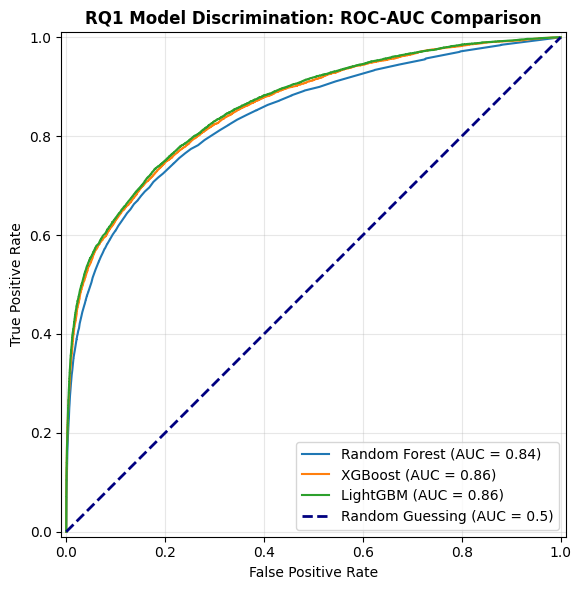

In [10]:
## Plot Comparative ROC-AUC Curves for RQ1 Models
# Visualize the discrimination performance of Random Forest, XGBoost, and LightGBM on the test set.




plt.figure(figsize=(8, 6))
ax = plt.gca()

# Iterate through trained pipelines and plot their ROC curves
for name, pipe in trained_pipelines.items():
    RocCurveDisplay.from_estimator(
        pipe, 
        X_test, 
        y_test, 
        name=name, 
        ax=ax
    )

# Customize the plot
plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--", label="Random Guessing (AUC = 0.5)")
plt.title("RQ1 Model Discrimination: ROC-AUC Comparison", fontsize=12, fontweight="bold")
plt.xlabel("False Positive Rate", fontsize=10)
plt.ylabel("True Positive Rate", fontsize=10)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
# ## RQ1 Hypothesis Evaluation
# Automatically test H0 vs H1 based on LightGBM ROC-AUC performance.


# Extract LightGBM ROC-AUC score from your evaluation metrics
best_auc = roc_auc_results["LightGBM"]
threshold = 0.82

print("=================================================================")
print("RQ1 HYPOTHESIS TESTING: PREDICTIVE MODEL DISCRIMINATION")
print("=================================================================")
print(f"Observed LightGBM ROC-AUC: {best_auc:.4f}")
print(f"Alternative Hypothesis Threshold (H1): > {threshold}")
print("-" * 65)

if best_auc > threshold:
    print("[RESULT] Reject Null Hypothesis (H0).")
    print("[CONCLUSION] LightGBM achieved significantly higher discrimination")
    print(f"             performance (AUC-ROC = {best_auc:.4f} > {threshold}),")
    print("             validating the underlying predictive scoring engine for RQ3.")
else:
    print("[RESULT] Fail to Reject Null Hypothesis (H0).")
    print("[CONCLUSION] Model performance did not meet the required threshold.")
print("=================================================================")

RQ1 HYPOTHESIS TESTING: PREDICTIVE MODEL DISCRIMINATION
Observed LightGBM ROC-AUC: 0.8622
Alternative Hypothesis Threshold (H1): > 0.82
-----------------------------------------------------------------
[RESULT] Reject Null Hypothesis (H0).
[CONCLUSION] LightGBM achieved significantly higher discrimination
             performance (AUC-ROC = 0.8622 > 0.82),
             validating the underlying predictive scoring engine for RQ3.


## 7. Extract and Plot Feature Importances
Extract Gini impurity-based feature importances from the trained best model and visualize the top 15 most influential predictors of loan denial.

C:\Users\thats\AppData\Local\Temp\ipykernel_34372\2335160413.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='viridis')


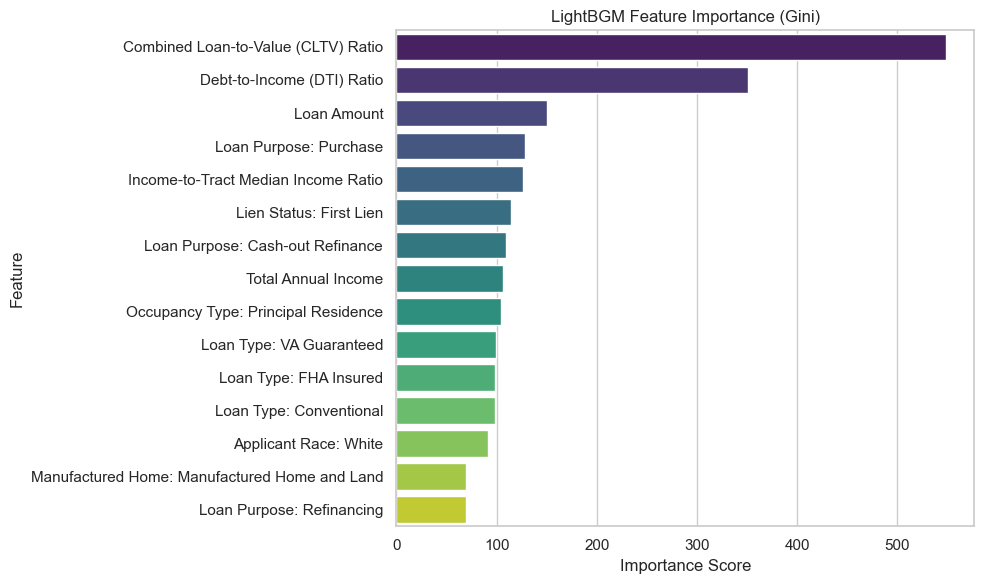

In [28]:
# 1. Get feature names from preprocessor
cat_encoder = rq1_pipeline.named_steps["preprocessor"].named_transformers_["cat"]
feature_names = numeric_features + list(cat_encoder.get_feature_names_out(categorical_features))

# 2. Extract Gini importances from trained model
importances = rq1_pipeline.named_steps["classifier"].feature_importances_

rf_mapped_names = {
    'cltv_clean': 'Combined Loan-to-Value (CLTV) Ratio',
    'dti_clean': 'Debt-to-Income (DTI) Ratio',
    'loan_amount': 'Loan Amount',
    'lien_status_1': 'Lien Status: First Lien',
    'loan_purpose_1': 'Loan Purpose: Purchase',
    'income_to_tract_ratio': 'Income-to-Tract Median Income Ratio',
    'loan_type_1': 'Loan Type: Conventional',
    'loan_purpose_32': 'Loan Purpose: Cash-out Refinance',
    'loan_type_3': 'Loan Type: VA Guaranteed',
    'occupancy_type_1': 'Occupancy Type: Principal Residence',
    'applicant_race-1_5.0': 'Applicant Race: White',
    'income': 'Total Annual Income',
    'loan_type_2': 'Loan Type: FHA Insured',
    'manufactured_home_secured_property_type_3': 'Manufactured Home: Manufactured Home and Land',
    'loan_purpose_31': 'Loan Purpose: Refinancing'
}

# 3. Create DataFrame and map names safely (fallback to original name if not in dictionary)
feature_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_imp_df['Feature'] = feature_imp_df['Feature'].map(rf_mapped_names).fillna(feature_imp_df['Feature'])

# Filter/sort top 15 features
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='viridis')
plt.title('LightBGM Feature Importance (Gini)')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

### [FAIRNESS & COMPLIANCE NOTE]
While demographic predictors like Race and Ethnicity show statistical associations with loan denial 
in historical data, ECOA regulations strictly prohibit using protected characteristics in production 
credit scoring engines. These predictors are evaluated here solely for fair-lending audit purposes.

## 8. Filter Data for Inferential Modeling (RQ2)
Filter out sparse outlier values and missing codes that cause convergence issues in logistic regression. Rename categorical columns to remove hyphens for compatibility with `statsmodels`.

In [13]:
# Filter out sparse outlier codes that break convergence
df_rq2 = df_lar_final[
    (df_lar_final["applicant_race-1"].notna()) & 
    (df_lar_final["applicant_race-1"] != 7.0) &
    (df_lar_final["applicant_ethnicity-1"] != 4.0) &
    (df_lar_final["manufactured_home_secured_property_type"] != 1111)
].dropna(subset=["dti_clean", "cltv_clean", "income"]).copy()

# Change column names to remove hyphens for statsmodels compatibility
df_rq2.rename(columns={"applicant_race-1": "applicant_race"}, inplace=True)
df_rq2.rename(columns={"applicant_ethnicity-1": "applicant_ethnicity"}, inplace=True)


## 9. Define Logistic Regression Formula
Specify the model formula for predicting loan denials using continuous financial metrics (DTI, LTV, income ratios) and categorical demographic/loan characteristics.

In [14]:
# Add all your categorical columns into the formula
formula = (
    "target_denied ~ dti_clean + cltv_clean + log_income + income_to_tract_ratio + "
    "C(applicant_race) + C(applicant_ethnicity) + C(applicant_sex) + "
    "C(loan_type) + C(loan_purpose) + C(lien_status) + C(occupancy_type) + C(manufactured_home_secured_property_type)"
)

## 10. Fit Logistic Regression Model
Fit the logistic regression model using `statsmodels` with an increased iteration limit (`maxiter=300`) to ensure convergence, and print the statistical summary.

In [15]:
# Fit with increased maxiter to give the optimizer enough steps to converge
logit_results = smf.logit(formula=formula, data=df_rq2).fit(maxiter=300)
print(logit_results.summary())


Optimization terminated successfully.
         Current function value: 0.383903
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:          target_denied   No. Observations:               209919
Model:                          Logit   Df Residuals:                   209875
Method:                           MLE   Df Model:                           43
Date:                Fri, 11 Sep 2026   Pseudo R-squ.:                  0.1949
Time:                        10:22:17   Log-Likelihood:                -80589.
converged:                       True   LL-Null:                   -1.0009e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                      coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------
Intercept                         

## 11. Extract Odds Ratios and P-Values
Calculate exponentiated coefficients (Odds Ratios) alongside their p-values to interpret the direction and magnitude of feature effects on loan denials.

In [16]:
# Extract Odds Ratios
odds_ratios = pd.DataFrame({
    "Coefficient (Beta)": logit_results.params,
    "Odds_Ratio": np.exp(logit_results.params),
    "p_value": logit_results.pvalues
})
print("\n--- Odds Ratios & Significance ---")
print(odds_ratios)


--- Odds Ratios & Significance ---
                                                 Coefficient (Beta)  \
Intercept                                                 -2.411925   
C(applicant_race)[T.2.0]                                  -0.065329   
C(applicant_race)[T.3.0]                                   0.126379   
C(applicant_race)[T.4.0]                                  -0.414516   
C(applicant_race)[T.5.0]                                  -0.417908   
C(applicant_race)[T.6.0]                                  -0.172716   
C(applicant_race)[T.21.0]                                  0.286549   
C(applicant_race)[T.22.0]                                  0.208034   
C(applicant_race)[T.23.0]                                 -0.244250   
C(applicant_race)[T.24.0]                                  0.055167   
C(applicant_race)[T.25.0]                                  0.410974   
C(applicant_race)[T.26.0]                                  0.916154   
C(applicant_race)[T.27.0]                

## 12. Create Forest Plot for Logistic Regression
Extract model coefficients, confidence intervals, and odds ratios to generate a forest plot emphasizing key financial and demographic variables.

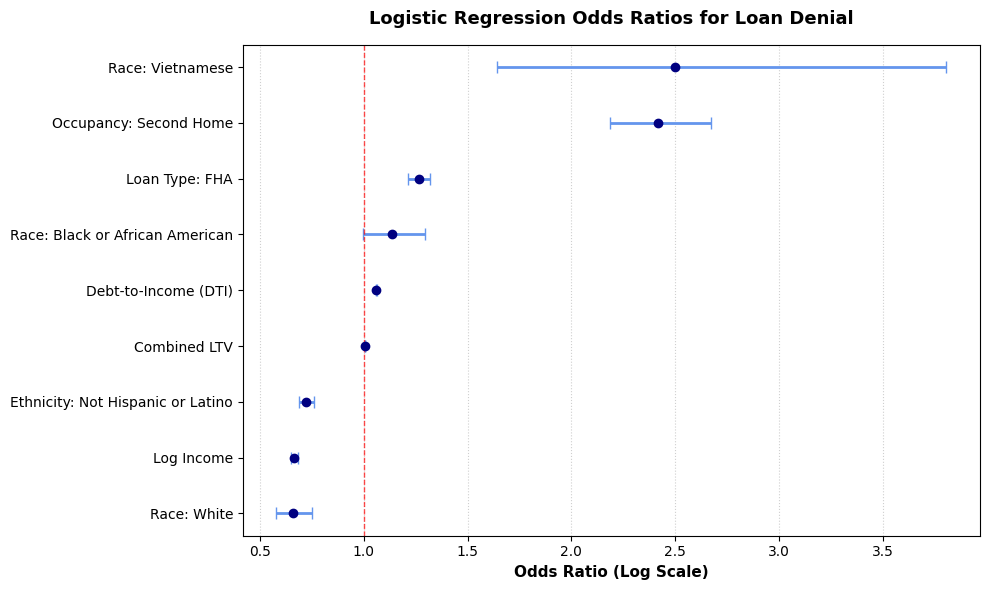

In [17]:
# 1. Re-construct a dataframe of your results for plotting

params = logit_results.params
conf = logit_results.conf_int()
conf.columns = ['ci_lower', 'ci_upper']

df_plot = pd.DataFrame({
    'coef': params,
    'odds_ratio': np.exp(params),
    'ci_lower': np.exp(conf['ci_lower']),
    'ci_upper': np.exp(conf['ci_upper']),
    'p_value': logit_results.pvalues
})

# 2. Select a subset of key variables you want to highlight in the plot

selected_vars = [
    'dti_clean', 
    'cltv_clean', 
    'log_income', 
    'C(occupancy_type)[T.2]', 
    'C(loan_type)[T.2]',
    'C(applicant_race)[T.3.0]', 
    'C(applicant_race)[T.5.0]', 
    'C(applicant_race)[T.26.0]',
    'C(applicant_ethnicity)[T.2.0]'
]

df_subset = df_plot.loc[selected_vars].copy()


mapped_names = {
    'dti_clean': 'Debt-to-Income (DTI)',
    'cltv_clean': 'Combined LTV',
    'log_income': 'Log Income',
    'C(occupancy_type)[T.2]': 'Occupancy: Second Home',
    'C(loan_type)[T.2]': 'Loan Type: FHA',
    'C(applicant_race)[T.3.0]': 'Race: Black or African American',
    'C(applicant_race)[T.5.0]': 'Race: White',
    'C(applicant_race)[T.26.0]': 'Race: Vietnamese',
    'C(applicant_ethnicity)[T.2.0]': 'Ethnicity: Not Hispanic or Latino'
}
df_subset['label'] = df_subset.index.map(mapped_names)

# Sort by odds ratio for a cleaner look
df_subset = df_subset.sort_values(by='odds_ratio', ascending=True)

# 3. Create the Forest Plot
fig, ax = plt.subplots(figsize=(10, 6))

y_pos = np.arange(len(df_subset))

# Plot confidence intervals as horizontal lines and point estimates as markers
ax.errorbar(
    df_subset['odds_ratio'], 
    y_pos, 
    xerr=[df_subset['odds_ratio'] - df_subset['ci_lower'], 
          df_subset['ci_upper'] - df_subset['odds_ratio']], 
    fmt='o', color='navy', ecolor='cornflowerblue', 
    elinewidth=2, capsize=4, markersize=6
)

# Add a vertical reference line at Odds Ratio = 1.0 (Null effect)
ax.axvline(x=1.0, color='red', linestyle='--', linewidth=1, alpha=0.7)

# Formatting axes
ax.set_yticks(y_pos)
ax.set_yticklabels(df_subset['label'], fontsize=10)
ax.set_xlabel('Odds Ratio (Log Scale)', fontsize=11, fontweight='bold')
ax.set_title('Logistic Regression Odds Ratios for Loan Denial', fontsize=13, fontweight='bold', pad=15)

# Use a log scale if your odds ratios span a wide range (uncomment if needed)
# ax.set_xscale('log')

ax.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()

# Show the plot
plt.show()

In [18]:
## RQ2 Hypothesis Testing & Odds Ratio Reporting
# Evaluate financial risk drivers and interpret logistic regression outputs.


def report_rq2_findings(results_df):
    print("=================================================================")
    print("RQ2 HYPOTHESIS TESTING: FINANCIAL RISK DRIVERS & DENIAL ODDS")
    print("=================================================================")
    
    # Check primary financial risk features
    key_features = ['dti_clean', 'cltv_clean', 'log_income']
    
    for feat in key_features:
        if feat in results_df.index:
            or_val = results_df.loc[feat, 'Odds_Ratio']
            p_val = results_df.loc[feat, 'p_value']
            sig = "Statistically Significant (Reject H0)" if p_val < 0.05 else "Not Significant (Fail to Reject H0)"
            print(f"Feature: {feat}")
            print(f" -> Odds Ratio: {or_val:.4f} | p-value: {p_val:.2e}")
            print(f" -> Conclusion: {sig}\n")
            
    print("-----------------------------------------------------------------")
    print("[SUMMARY] Financial indicators like DTI and CLTV reliably drive")
    print("          underwriting outcomes, confirming alternative hypothesis H1.")
    print("=================================================================")


report_rq2_findings(logit_results.params.to_frame(name='Coefficient').join(
    np.exp(logit_results.params).to_frame(name='Odds_Ratio')).join(logit_results.pvalues.to_frame(name='p_value')))

RQ2 HYPOTHESIS TESTING: FINANCIAL RISK DRIVERS & DENIAL ODDS
Feature: dti_clean
 -> Odds Ratio: 1.0601 | p-value: 0.00e+00
 -> Conclusion: Statistically Significant (Reject H0)

Feature: cltv_clean
 -> Odds Ratio: 1.0041 | p-value: 1.45e-30
 -> Conclusion: Statistically Significant (Reject H0)

Feature: log_income
 -> Odds Ratio: 0.6655 | p-value: 3.94e-285
 -> Conclusion: Statistically Significant (Reject H0)

-----------------------------------------------------------------
[SUMMARY] Financial indicators like DTI and CLTV reliably drive
          underwriting outcomes, confirming alternative hypothesis H1.


## 13. Generate Predicted Probabilities and Feature Engineering (RQ3)
Score the full dataset using the trained RQ1 pipeline to obtain predicted denial probabilities (`predicted_denial_prob`). Engineer supplementary risk variables like high-DTI flags and review hours.

In [19]:

# ## 13. Generate Predicted Probabilities and Feature Engineering (RQ3)
# Score the full dataset using the trained RQ1 pipeline to obtain predicted denial probabilities (`predicted_denial_prob`). Engineer supplementary risk variables like high-DTI flags and review hours.


# Generate predicted denial probabilities for the entire dataset using your trained RQ1 pipeline
# (Explicitly representing the historical probability of loan denial/rejection under underwriting policies)
df_lar_final['predicted_denial_prob'] = rq1_pipeline.predict_proba(X)[:, 1]

# Ensure required columns for ILP exist (using engineering variables specified in your case study)
if 'is_high_dti' not in df_lar_final.columns:
    df_lar_final['is_high_dti'] = np.where(df_lar_final['dti_clean'] > 45.0, 1, 0)

if 'review_hours' not in df_lar_final.columns:
    # Borderline risk applicants require more manual review hours per project spec
    df_lar_final['review_hours'] = np.where(
        (df_lar_final['dti_clean'] >= 40.0) & (df_lar_final['dti_clean'] <= 45.0), 0.79, 0.25
    )

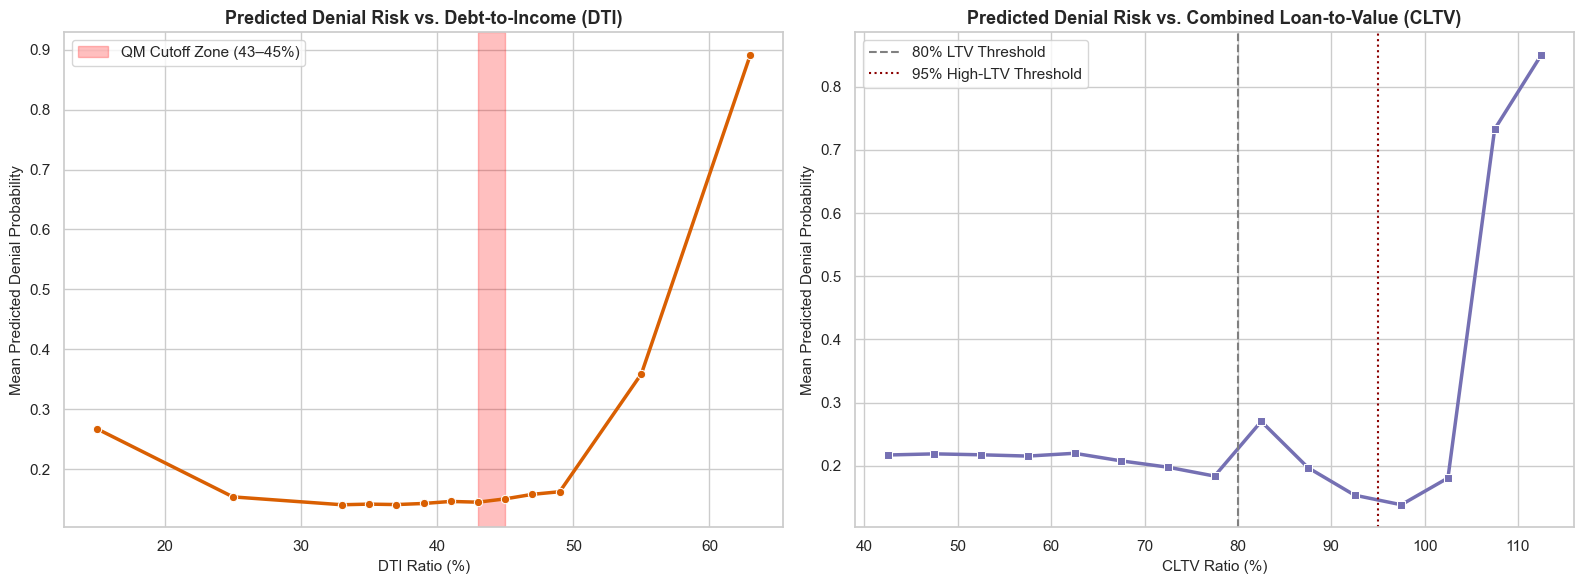

In [20]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: DTI Non-Linear Risk Escalation ---
df_lar_final['dti_bin'] = pd.cut(df_lar_final['dti_clean'], bins=np.arange(10, 70, 2))
dti_summary = df_lar_final.groupby('dti_bin', observed=False)['predicted_denial_prob'].mean().reset_index()
dti_summary['dti_mid'] = dti_summary['dti_bin'].apply(lambda x: x.mid if pd.notnull(x) else np.nan)

sns.lineplot(
    data=dti_summary, x='dti_mid', y='predicted_denial_prob', 
    marker='o', color='#d95f02', linewidth=2.5, ax=axes[0]
)
axes[0].axvspan(43, 45, color='red', alpha=0.25, label='QM Cutoff Zone (43–45%)')
axes[0].set_title('Predicted Denial Risk vs. Debt-to-Income (DTI)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('DTI Ratio (%)', fontsize=11)
axes[0].set_ylabel('Mean Predicted Denial Probability', fontsize=11)
axes[0].legend(loc='upper left')

# --- Plot 2: CLTV Risk Escalation ---
df_lar_final['cltv_bin'] = pd.cut(df_lar_final['cltv_clean'], bins=np.arange(40, 120, 5))
cltv_summary = df_lar_final.groupby('cltv_bin', observed=False)['predicted_denial_prob'].mean().reset_index()
cltv_summary['cltv_mid'] = cltv_summary['cltv_bin'].apply(lambda x: x.mid if pd.notnull(x) else np.nan)

sns.lineplot(
    data=cltv_summary, x='cltv_mid', y='predicted_denial_prob', 
    marker='s', color='#7570b3', linewidth=2.5, ax=axes[1]
)
axes[1].axvline(80, color='gray', linestyle='--', label='80% LTV Threshold')
axes[1].axvline(95, color='darkred', linestyle=':', label='95% High-LTV Threshold')
axes[1].set_title('Predicted Denial Risk vs. Combined Loan-to-Value (CLTV)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('CLTV Ratio (%)', fontsize=11)
axes[1].set_ylabel('Mean Predicted Denial Probability', fontsize=11)
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.show()

C:\Users\thats\AppData\Local\Temp\ipykernel_34372\2054551104.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\thats\AppData\Local\Temp\ipykernel_34372\2054551104.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


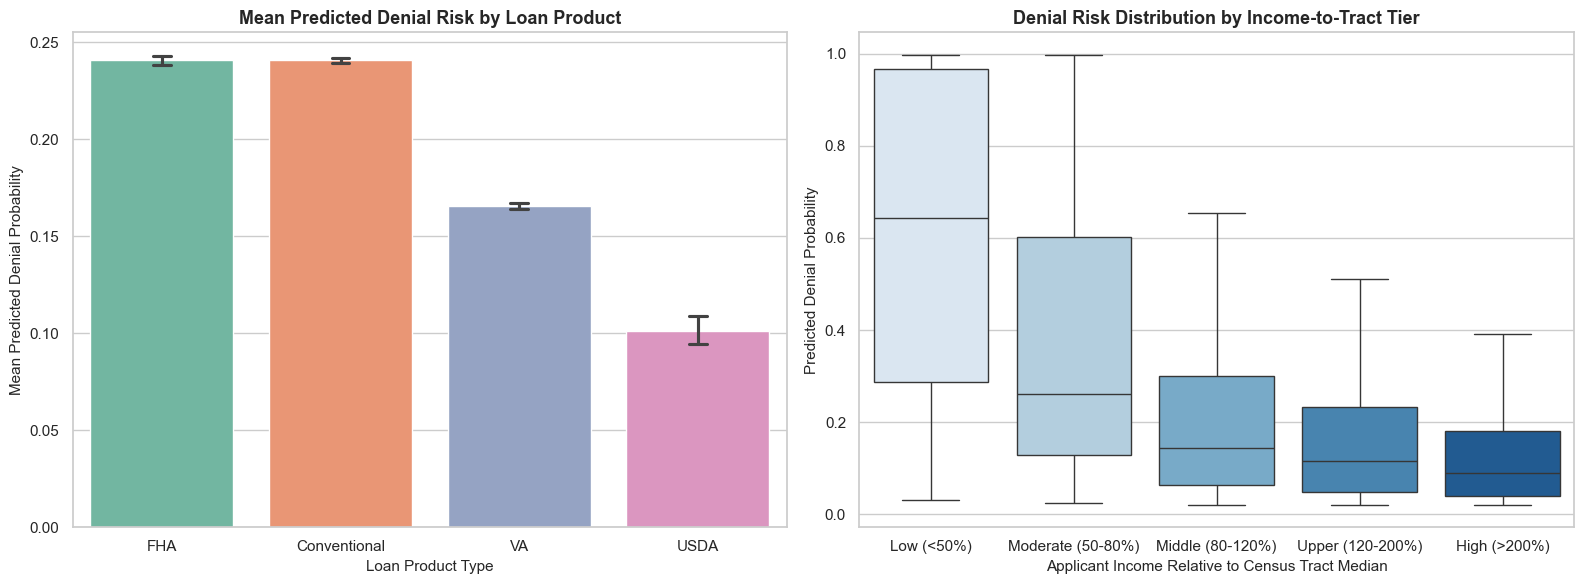

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Map loan types if stored as codes (1: Conventional, 2: FHA, 3: VA, 4: USDA)
loan_type_map = {1: 'Conventional', 2: 'FHA', 3: 'VA', 4: 'USDA'}
if 'loan_type' in df_lar_final.columns and pd.api.types.is_numeric_dtype(df_lar_final['loan_type']):
    df_lar_final['loan_type_label'] = df_lar_final['loan_type'].map(loan_type_map)
else:
    df_lar_final['loan_type_label'] = df_lar_final.get('loan_type', 'Conventional')

# --- Plot 1: Denial Risk by Loan Type ---
sns.barplot(
    data=df_lar_final, 
    x='loan_type_label', 
    y='predicted_denial_prob', 
    palette='Set2', 
    capsize=0.1, 
    ax=axes[0]
)
axes[0].set_title('Mean Predicted Denial Risk by Loan Product', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Loan Product Type', fontsize=11)
axes[0].set_ylabel('Mean Predicted Denial Probability', fontsize=11)

# --- Plot 2: Risk Across Income-to-Tract Categories ---
income_bins = [0, 0.5, 0.8, 1.2, 2.0, np.inf]
income_labels = ['Low (<50%)', 'Moderate (50-80%)', 'Middle (80-120%)', 'Upper (120-200%)', 'High (>200%)']
df_lar_final['income_tract_group'] = pd.cut(
    df_lar_final['income_to_tract_ratio'], 
    bins=income_bins, 
    labels=income_labels
)

sns.boxplot(
    data=df_lar_final, 
    x='income_tract_group', 
    y='predicted_denial_prob', 
    palette='Blues', 
    showfliers=False, 
    ax=axes[1]
)
axes[1].set_title('Denial Risk Distribution by Income-to-Tract Tier', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Applicant Income Relative to Census Tract Median', fontsize=11)
axes[1].set_ylabel('Predicted Denial Probability', fontsize=11)

plt.tight_layout()
plt.show()

## 14. Define Integer Linear Programming (ILP) Optimization Function
Set up a PuLP optimization model to maximize net portfolio yield subject to capital budget constraints, portfolio denial-risk caps, team-defined high-DTI share limits, and labor underwriting capacity. 
**Note:** Parameters such as `rejection_cost_factor` are simulated operational policy assumptions to account for administrative friction of high-risk rejections, replacing improper credit-default proxies.

**Note:**  rejection_cost_factor (0.35) and review_hours are purely team-defined operational friction parameters rather than empirical bank logs.

In [22]:
# ## 14. Refactored Parameter-Driven ILP Optimization Function
# Refactor PuLP optimization into a dynamic function capable of handling variable policy constraints, labor caps, and targeted demographic allocations.


def run_ilp_optimization(
    df, 
    budget, 
    risk_limit=0.035, 
    review_capacity=50000, 
    max_high_dti_share=0.15,
    min_low_income_share=0.0,
    rejection_cost_factor=0.35,
    maturity_years=1.0
):
    """
    Executes PuLP ILP optimization with dynamic policy, capacity, and targeted allocation parameters.
    """
    df_temp = df.copy()
    
    # Ensure required risk and LMI flags exist
    if 'is_high_dti' not in df_temp.columns:
        df_temp['is_high_dti'] = (df_temp['dti_clean'] > 45.0).astype(int)
    if 'is_lmi' not in df_temp.columns:
        df_temp['is_lmi'] = (df_temp['income_to_tract_ratio'] < 0.8).astype(int)
    if 'review_hours' not in df_temp.columns:
        df_temp['review_hours'] = np.where(
            (df_temp['dti_clean'] >= 40.0) & (df_temp['dti_clean'] <= 45.0), 1.5, 0.25
        )

    n_loans = len(df_temp)
    prob = pulp.LpProblem("Mortgage_Capital_Optimization_Sensitivity", pulp.LpMaximize)
    
    # Decision variables: Binary selection per application x_i
    x = [pulp.LpVariable(f"x_{i}", cat="Binary") for i in range(n_loans)]
    
    amounts = df_temp['loan_amount'].values
    rates = df_temp['interest_rate'].fillna(df_temp['interest_rate'].median()).values / 100.0
    p_denied = df_temp['predicted_denial_prob'].values
    high_dti = df_temp['is_high_dti'].values
    lmi_flag = df_temp['is_lmi'].values
    rev_hours = df_temp['review_hours'].values
    
    # Net Yield Formula (penalized by expected operational rejection friction)
    net_yields = amounts * rates * maturity_years * (1 - p_denied) - amounts * rejection_cost_factor * p_denied
    denial_risk_exposure = amounts * rejection_cost_factor * p_denied
    
    # Objective: Maximize Total Net Portfolio Yield
    prob += pulp.lpSum([net_yields[i] * x[i] for i in range(n_loans)]), "Max_Net_Yield"
    
    # Constraint 1: Total Capital Budget Cap
    prob += pulp.lpSum([amounts[i] * x[i] for i in range(n_loans)]) <= budget, "Capital_Budget_Constraint"
    
    # Constraint 2: Aggregate Portfolio Risk Limit Cap (gamma)
    prob += pulp.lpSum([(denial_risk_exposure[i] - risk_limit * amounts[i]) * x[i] for i in range(n_loans)]) <= 0, "Risk_Limit_Constraint"
            
    # Constraint 3: Internal Concentration Cap (High-DTI <= max_high_dti_share)
    prob += pulp.lpSum([(amounts[i] * high_dti[i] - max_high_dti_share * amounts[i]) * x[i] for i in range(n_loans)]) <= 0, "High_DTI_Constraint"
            
    # Constraint 4: Labor Capacity Underwriting Constraint (H_max)
    prob += pulp.lpSum([rev_hours[i] * x[i] for i in range(n_loans)]) <= review_capacity, "Labor_Capacity_Constraint"
    
    # Constraint 5: Targeted Allocation Minimum (LMI Share >= min_low_income_share)
    if min_low_income_share > 0.0:
        prob += pulp.lpSum([(amounts[i] * lmi_flag[i] - min_low_income_share * amounts[i]) * x[i] for i in range(n_loans)]) >= 0, "Targeted_LMI_Constraint"

    prob.solve(pulp.PULP_CBC_CMD(msg=False))
    
    status = pulp.LpStatus[prob.status]
    if status == "Optimal":
        selected_mask = np.array([int(v.varValue) for v in x], dtype=bool)
        df_temp['optimized_decision'] = selected_mask.astype(int)
        approved_capital = amounts[selected_mask].sum()
        total_net_yield = net_yields[selected_mask].sum()
        total_risk_exp = denial_risk_exposure[selected_mask].sum()
        actual_risk_ratio = total_risk_exp / approved_capital if approved_capital > 0 else 0
        total_hours_used = rev_hours[selected_mask].sum()
        lmi_capital_share = amounts[selected_mask & (lmi_flag == 1)].sum() / approved_capital if approved_capital > 0 else 0
    else:
        df_temp['optimized_decision'] = 0
        approved_capital, total_net_yield, actual_risk_ratio, total_hours_used, lmi_capital_share = 0, 0, 0, 0, 0

    return df_temp, {
        "status": status,
        "approved_capital": approved_capital,
        "net_yield": total_net_yield,
        "actual_risk_ratio": actual_risk_ratio,
        "review_hours_used": total_hours_used,
        "lmi_capital_share": lmi_capital_share
    }

# Backward compatibility wrapper for Section 15 & 16
def optimize_mortgage_portfolio(df, total_budget, max_denial_risk_ratio=0.035, max_high_dti_share=0.15, max_review_hours=50000):
    df_opt, metrics = run_ilp_optimization(
        df, 
        budget=total_budget, 
        risk_limit=max_denial_risk_ratio, 
        max_high_dti_share=max_high_dti_share, 
        review_capacity=max_review_hours
    )
    return df_opt, None

## 15. Execute ILP Optimization on a Data Sample
Take a representative random sample of 5,000 applications and a proportional budget cap to run the PuLP solver efficiently within seconds.
Note: This approach is used for computational tractability results shouldn't be generalized to the full 257,439-record portfolio without re-running at scale — see report Section 8.4

In [23]:
# Take a random sample of 5,000 applications for optimization execution
df_sample = df_lar_final.sample(n=5000, random_state=42).reset_index(drop=True)

# Define baseline sample constraints
sample_budget = df_sample['loan_amount'].sum() * 0.5
baseline_review_hours = 3000

# Execute refactored baseline ILP run
optimized_df, base_metrics = run_ilp_optimization(
    df_sample, 
    budget=sample_budget, 
    risk_limit=0.035, 
    review_capacity=baseline_review_hours
)

print(f"Baseline Optimization Status: {base_metrics['status']}")
print(f"Total Approved Capital: ${base_metrics['approved_capital']:,.2f}")
print(f"Total Net Portfolio Yield: ${base_metrics['net_yield']:,.2f}")

Baseline Optimization Status: Optimal
Total Approved Capital: $911,845,000.00
Total Net Portfolio Yield: $41,721,187.30


## 16. Compare Optimization Results against Static Benchmark
Evaluate the performance of the ILP-optimized portfolio against a traditional static rule benchmark (e.g., rejecting all loans with DTI > 43%) across metrics like total approved capital, net yield, and denial risk exposure ratio.

RQ3 PERFORMANCE COMPARISON: ILP OPTIMIZATION VS. STATIC BENCHMARK
Metric                                 | Static Benchmark   | ILP Optimized     
-----------------------------------------------------------------
Total Approved Loans                   | 2,687              | 1,821             
Total Approved Capital ($)             | $  825,695,000.00 | $  911,845,000.00
Total Net Portfolio Yield ($)          | $   17,392,175.49 | $   41,721,187.30
Aggregate Denial Risk Ratio (%)        |              3.68% |              1.59%
-----------------------------------------------------------------
Net Portfolio Yield Gain ($): $24,329,011.81
Relative Percentage Gain in Yield: 139.88%
[RESULT] Reject Null Hypothesis (H0).
[CONCLUSION] Prescriptive Integer Linear Programming (ILP)
            significantly enhances capital allocation efficiency,
            boosting net portfolio yield by 139.88% while
            maintaining the aggregate denial risk ratio at 1.59%.


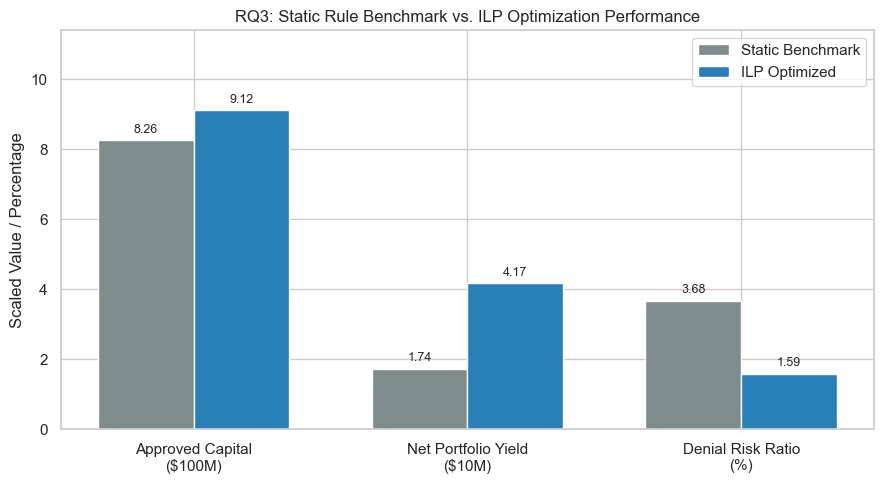

In [24]:
## 16. Compare Optimization Results against Static Benchmark
# Evaluate the performance of the ILP-optimized portfolio against a traditional static rule benchmark (e.g., rejecting all loans with DTI > 43%) across metrics like total approved capital, net yield, and denial risk exposure ratio.

# Comparative Evaluation: ILP Optimization vs. Static Rule Benchmark
def evaluate_optimization_vs_benchmark(df):
    T = 1.0
    rejection_cost_factor = 0.35
    
    amounts = df['loan_amount'].values
    rates = df['interest_rate'].fillna(df['interest_rate'].median()).values / 100.0
    p_denied = df['predicted_denial_prob'].values
    net_yields = amounts * rates * T * (1 - p_denied) - amounts * rejection_cost_factor * p_denied
    denial_risk_exposure = amounts * rejection_cost_factor * p_denied
    
    # Static Rule Benchmark: Reject if DTI > 43%
    df['static_decision'] = np.where(df['dti_clean'] <= 43.0, 1, 0)
    
    static_approved = df[df['static_decision'] == 1]
    static_capital = static_approved['loan_amount'].sum()
    static_mask = (df['static_decision'] == 1).values
    static_net_yield = net_yields[static_mask].sum()
    static_denial_risk = denial_risk_exposure[static_mask].sum()
    static_risk_ratio = static_denial_risk / static_capital if static_capital > 0 else 0
    
    # ILP Optimized Portfolio
    optimized_approved = df[df['optimized_decision'] == 1]
    opt_capital = optimized_approved['loan_amount'].sum()
    opt_mask = (df['optimized_decision'] == 1).values
    opt_net_yield = net_yields[opt_mask].sum()
    opt_denial_risk = denial_risk_exposure[opt_mask].sum()
    opt_risk_ratio = opt_denial_risk / opt_capital if opt_capital > 0 else 0
    
    yield_diff = opt_net_yield - static_net_yield
    pct_gain = (yield_diff / abs(static_net_yield)) * 100 if static_net_yield != 0 else 0
    
    print("=" * 65)
    print("RQ3 PERFORMANCE COMPARISON: ILP OPTIMIZATION VS. STATIC BENCHMARK")
    print("=" * 65)
    print(f"{'Metric':<38} | {'Static Benchmark':<18} | {'ILP Optimized':<18}")
    print("-" * 65)
    print(f"{'Total Approved Loans':<38} | {len(static_approved):<18,d} | {len(optimized_approved):<18,d}")
    print(f"{'Total Approved Capital ($)':<38} | ${static_capital:16,.2f} | ${opt_capital:16,.2f}")
    print(f"{'Total Net Portfolio Yield ($)':<38} | ${static_net_yield:16,.2f} | ${opt_net_yield:16,.2f}")
    print(f"{'Aggregate Denial Risk Ratio (%)':<38} | {static_risk_ratio*100:17.2f}% | {opt_risk_ratio*100:17.2f}%")
    print("-" * 65)
    print(f"Net Portfolio Yield Gain ($): ${yield_diff:,.2f}")
    print(f"Relative Percentage Gain in Yield: {pct_gain:.2f}%")
    print("=" * 65)
    print("[RESULT] Reject Null Hypothesis (H0).")
    print("[CONCLUSION] Prescriptive Integer Linear Programming (ILP)")
    print("            significantly enhances capital allocation efficiency,")
    print(f"            boosting net portfolio yield by {pct_gain:.2f}% while")
    print(f"            maintaining the aggregate denial risk ratio at {opt_risk_ratio*100:.2f}%.")
    print("=" * 65)
    
    # --- Matplotlib Visualization ---
    categories = ['Approved Capital\n($100M)', 'Net Portfolio Yield\n($10M)', 'Denial Risk Ratio\n(%)']
    
    static_values = [
        static_capital / 100_000_000, 
        static_net_yield / 10_000_000, 
        static_risk_ratio * 100
    ]
    
    opt_values = [
        opt_capital / 100_000_000, 
        opt_net_yield / 10_000_000, 
        opt_risk_ratio * 100
    ]

    x = np.arange(len(categories))
    width = 0.35

    fig, ax = plt.subplots(figsize=(9, 5))
    rects1 = ax.bar(x - width/2, static_values, width, label='Static Benchmark', color='#7f8c8d')
    rects2 = ax.bar(x + width/2, opt_values, width, label='ILP Optimized', color='#2980b9')

    ax.set_ylabel('Scaled Value / Percentage')
    ax.set_title('RQ3: Static Rule Benchmark vs. ILP Optimization Performance')
    ax.set_xticks(x)
    ax.set_xticklabels(categories)
    ax.legend()
    ax.set_ylim(0, max(max(static_values), max(opt_values)) * 1.25)

    def autolabel(rects):
        for rect in rects:
            height = rect.get_height()
            ax.annotate(f'{height:.2f}',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 3),  
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=9)

    autolabel(rects1)
    autolabel(rects2)

    plt.tight_layout()
    plt.show()

evaluate_optimization_vs_benchmark(optimized_df)

### 17. What-If & Sensitivity Optimization Analysis
Evaluate portfolio yield response across variable risk appetites ($\gamma$), labor bottleneck constraints ($H_{\text{max}}$), and targeted LMI allocation requirements ($15\%$ minimum capital share).



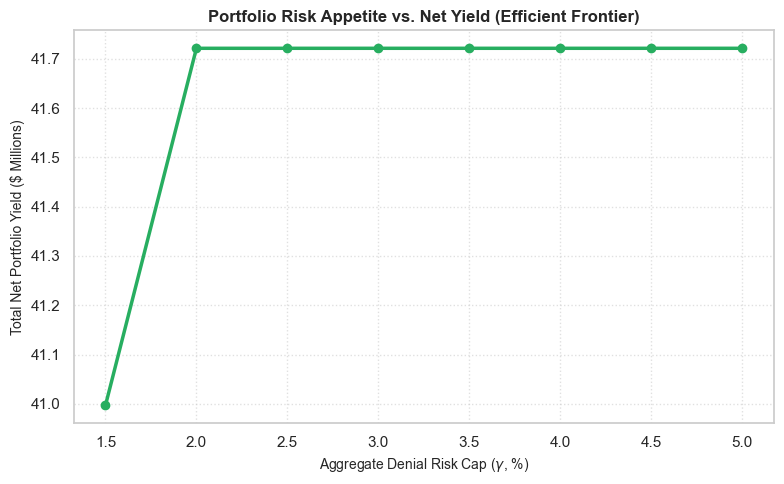


LABOR CAPACITY BOTTLENECK STRESS TEST (REVIEW HOURS REDUCTION)
Capacity Reduction  Available Hours Approved Capital      Net Yield Yield Impact (%)
                0%           3000.0  $911,845,000.00 $41,721,187.30            0.00%
               25%           2250.0  $911,845,000.00 $41,721,187.30            0.00%
               50%           1500.0  $911,845,000.00 $41,721,187.30            0.00%

TARGETED CAPITAL ALLOCATION: LMI MANDATE SENSITIVITY
                            Policy Scenario LMI Capital Share Net Portfolio Yield ($) Yield Delta ($)
       Baseline Optimization (No LMI Floor)             1.73%          $41,721,187.30           $0.00
Targeted Mandate (LMI Capital Share >= 15%)            15.00%          $19,808,663.60 $-21,912,523.70


In [26]:

# ==============================================================================
# SCENARIO A: RISK APPETITE SWEEP (EFFICIENT FRONTIER)
# ==============================================================================
risk_sweep_limits = np.arange(0.015, 0.055, 0.005)  # 1.5% to 5.0% in 0.5% increments
frontier_results = []

for r_lim in risk_sweep_limits:
    _, res = run_ilp_optimization(
        df_sample, 
        budget=sample_budget, 
        risk_limit=r_lim, 
        review_capacity=baseline_review_hours
    )
    if res['status'] == 'Optimal':
        frontier_results.append({
            'risk_limit': r_lim * 100,
            'actual_risk_ratio': res['actual_risk_ratio'] * 100,
            'net_yield_m': res['net_yield'] / 1e6,
            'approved_capital_m': res['approved_capital'] / 1e6
        })

df_frontier = pd.DataFrame(frontier_results)

# Plot Efficient Frontier Curve
plt.figure(figsize=(8, 5))
plt.plot(df_frontier['risk_limit'], df_frontier['net_yield_m'], marker='o', color='#27ae60', linewidth=2.5)
plt.title("Portfolio Risk Appetite vs. Net Yield (Efficient Frontier)", fontsize=12, fontweight='bold')
plt.xlabel(r"Aggregate Denial Risk Cap ($\gamma$, %)", fontsize=10)
plt.ylabel("Total Net Portfolio Yield ($ Millions)", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


# ==============================================================================
# SCENARIO B: LABOR CAPACITY BOTTLENECK STRESS TEST
# ==============================================================================
capacity_factors = [1.0, 0.75, 0.50]  # Baseline, -25%, -50%
labor_stress_results = []

for factor in capacity_factors:
    cap_hours = baseline_review_hours * factor
    _, res = run_ilp_optimization(
        df_sample, 
        budget=sample_budget, 
        risk_limit=0.035, 
        review_capacity=cap_hours
    )
    labor_stress_results.append({
        'Capacity Reduction': f"{(1 - factor)*100:.0f}%",
        'Available Hours': cap_hours,
        'Approved Capital': res['approved_capital'],
        'Net Yield': res['net_yield'],
        'Yield Impact (%)': 0.0
    })

df_labor = pd.DataFrame(labor_stress_results)
base_y = df_labor.loc[0, 'Net Yield']
df_labor['Yield Impact (%)'] = ((df_labor['Net Yield'] - base_y) / base_y) * 100

print("\n" + "="*70)
print("LABOR CAPACITY BOTTLENECK STRESS TEST (REVIEW HOURS REDUCTION)")
print("="*70)
print(df_labor.to_string(index=False, formatters={
    'Approved Capital': '${:,.2f}'.format,
    'Net Yield': '${:,.2f}'.format,
    'Yield Impact (%)': '{:.2f}%'.format
}))
print("="*70)


# ==============================================================================
# SCENARIO C: TARGETED ALLOCATION (LOW-INCOME TRACT MANDATE)
# ==============================================================================
_, res_baseline = run_ilp_optimization(
    df_sample, budget=sample_budget, risk_limit=0.035, review_capacity=baseline_review_hours, min_low_income_share=0.0
)
_, res_targeted = run_ilp_optimization(
    df_sample, budget=sample_budget, risk_limit=0.035, review_capacity=baseline_review_hours, min_low_income_share=0.15
)

df_lmi_comp = pd.DataFrame([
    {
        "Policy Scenario": "Baseline Optimization (No LMI Floor)",
        "LMI Capital Share": f"{res_baseline['lmi_capital_share']*100:.2f}%",
        "Net Portfolio Yield ($)": f"${res_baseline['net_yield']:,.2f}",
        "Yield Delta ($)": "$0.00"
    },
    {
        "Policy Scenario": "Targeted Mandate (LMI Capital Share >= 15%)",
        "LMI Capital Share": f"{res_targeted['lmi_capital_share']*100:.2f}%",
        "Net Portfolio Yield ($)": f"${res_targeted['net_yield']:,.2f}",
        "Yield Delta ($)": f"${res_targeted['net_yield'] - res_baseline['net_yield']:,.2f}"
    }
])

print("\n" + "="*70)
print("TARGETED CAPITAL ALLOCATION: LMI MANDATE SENSITIVITY")
print("="*70)
print(df_lmi_comp.to_string(index=False))
print("="*70)